**1- Kasu honetarako zein metodo da hobeagoa: z-score edo IQR? Zergatik?**

**IQR.** `fare` oso asimetrikoa da (skew = 4.79). Z-score-ak batezbestekoa eta desbideratze estandarra erabiltzen ditu, eta bi horiek outlierrek berek "puzten" dituzte (txartel garesti batzuek batezbestekoa eta std igotzen dituzte), beraz outlier askok ez dute z > 3 gainditzen (20 bakarrik detektatzen ditu). IQR-k kuartilak (Q1, Q3) erabiltzen ditu, eta horiek ez dira muturreko balioengatik aldatzen → sendoagoa da banaketa asimetrikoetan (116 outlier detektatzen ditu).

**2- Capping-ak zer egin du?**

Muga (IQR) gainditzen duten balioak **mugaren balioan mozten** ditu (`clip(low, high)`), errenkadarik ezabatu gabe. 65.63 baino handiagoak ziren fare guztiak 65.63 bihurtu dira (gehienezkoa 512 → 65.63).

**3- Log-transformazioa zer egin du?**

Balio handiak **konprimitzen** ditu eta txikiak ia ez ditu aldatzen: 10 eta 500 arteko aldea askoz txikiagoa bihurtzen da. Ondorioz asimetria 4.79tik 0.39ra jaitsi da eta banaketa simetrikoagoa da. Ez du daturik ezabatzen edo mozten; eskala aldatzen du.

**4- Logaritmo funtzioa aplikatzerakoan zergatik erabili da log1p(fare) eta ez log(fare)?**

Titanic-en badaude `fare = 0` duten bidaiariak, eta `log(0) = -∞` da (ezin da erabili). `log1p(x) = log(1 + x)` denez, `log1p(0) = log(1) = 0` → zeroak arazorik gabe tratatzen dira.

**5- Azkeneko histogramak azaldu.**

- **Ezkerrekoa (jatorrizkoa):** ia bidaiari guztiak lehen barretan pilatuta daude (0–50), eta isats luze bat dago 512raino. Eskala outlierrek markatzen dutenez, banaketaren gehiengoa ia ez da ikusten.
- **Eskuinekoa (log ondoren):** balioak tarte txikiago batean (0–6,2) zabaltzen dira eta banaketa ia simetrikoa da; orain datuen egitura ikusten da. Hori da modelo askorentzat (lineala, KNN...) nahiago dugun forma.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
df = sns.load_dataset("titanic")
df.head() # 891 errenkada × 15 zutabe
# edo fitxategia igo eta df = pd.read_csv("titanic.csv")
fare = df['fare'].dropna()

In [2]:
z = np.abs(stats.zscore(fare))
print('z-score bidezko outlierrak:', int((z > 3).sum()))

z-score bidezko outlierrak: 20


In [3]:
Q1, Q3 = fare.quantile(0.25), fare.quantile(0.75)
IQR = Q3 - Q1
low, high = Q1 - 1.5*IQR, Q3 + 1.5*IQR
print('IQR mugak:', round(low,2), round(high,2))
print('IQR bidezko outlierrak:', int(((fare < low) | (fare >
high)).sum()))

IQR mugak: -26.72 65.63
IQR bidezko outlierrak: 116


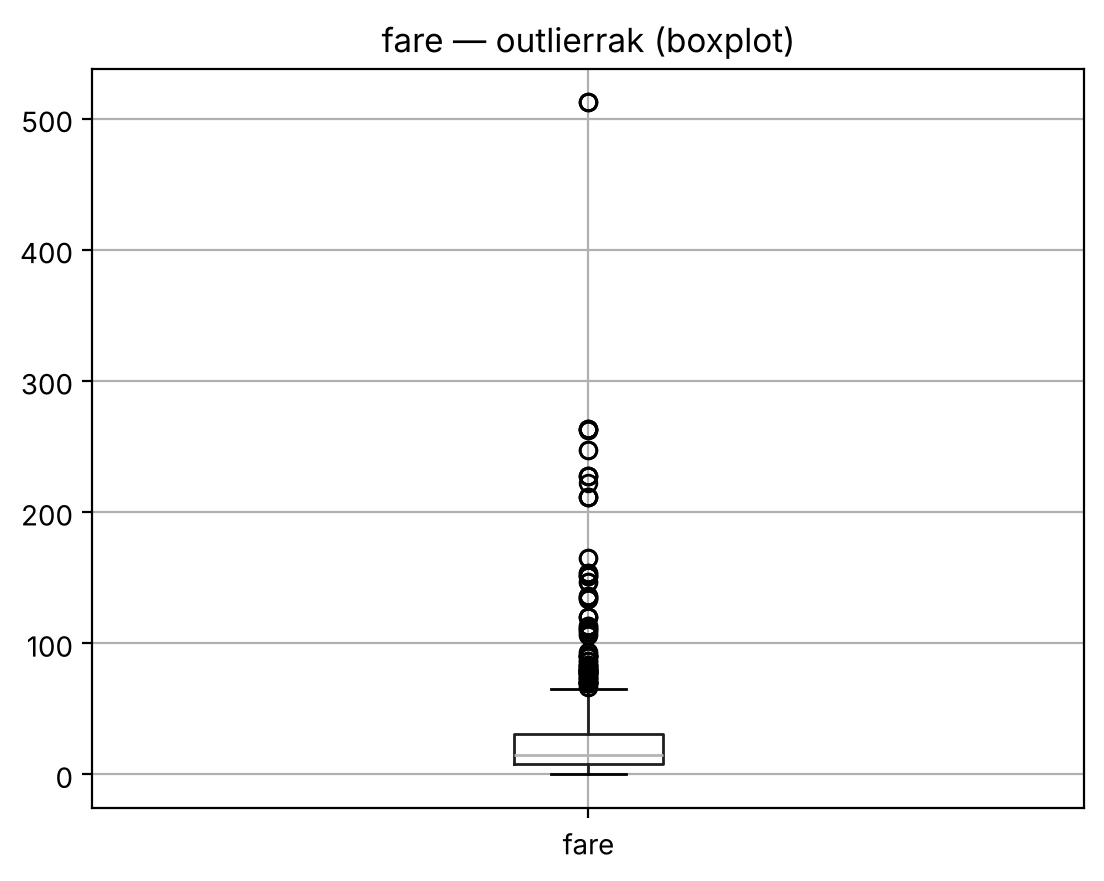

In [4]:
df.boxplot(column='fare')
plt.title('fare — outlierrak (boxplot)'); plt.show()

In [5]:
fare_cap = fare.clip(low, high)
print('Gehienezkoa mugatu ondoren:', round(fare_cap.max(),2))

Gehienezkoa mugatu ondoren: 65.63


In [6]:
fare_log = np.log1p(fare)
print('Asimetria aurretik:', round(fare.skew(),2),
'| log ondoren:', round(fare_log.skew(),2))

Asimetria aurretik: 4.79 | log ondoren: 0.39


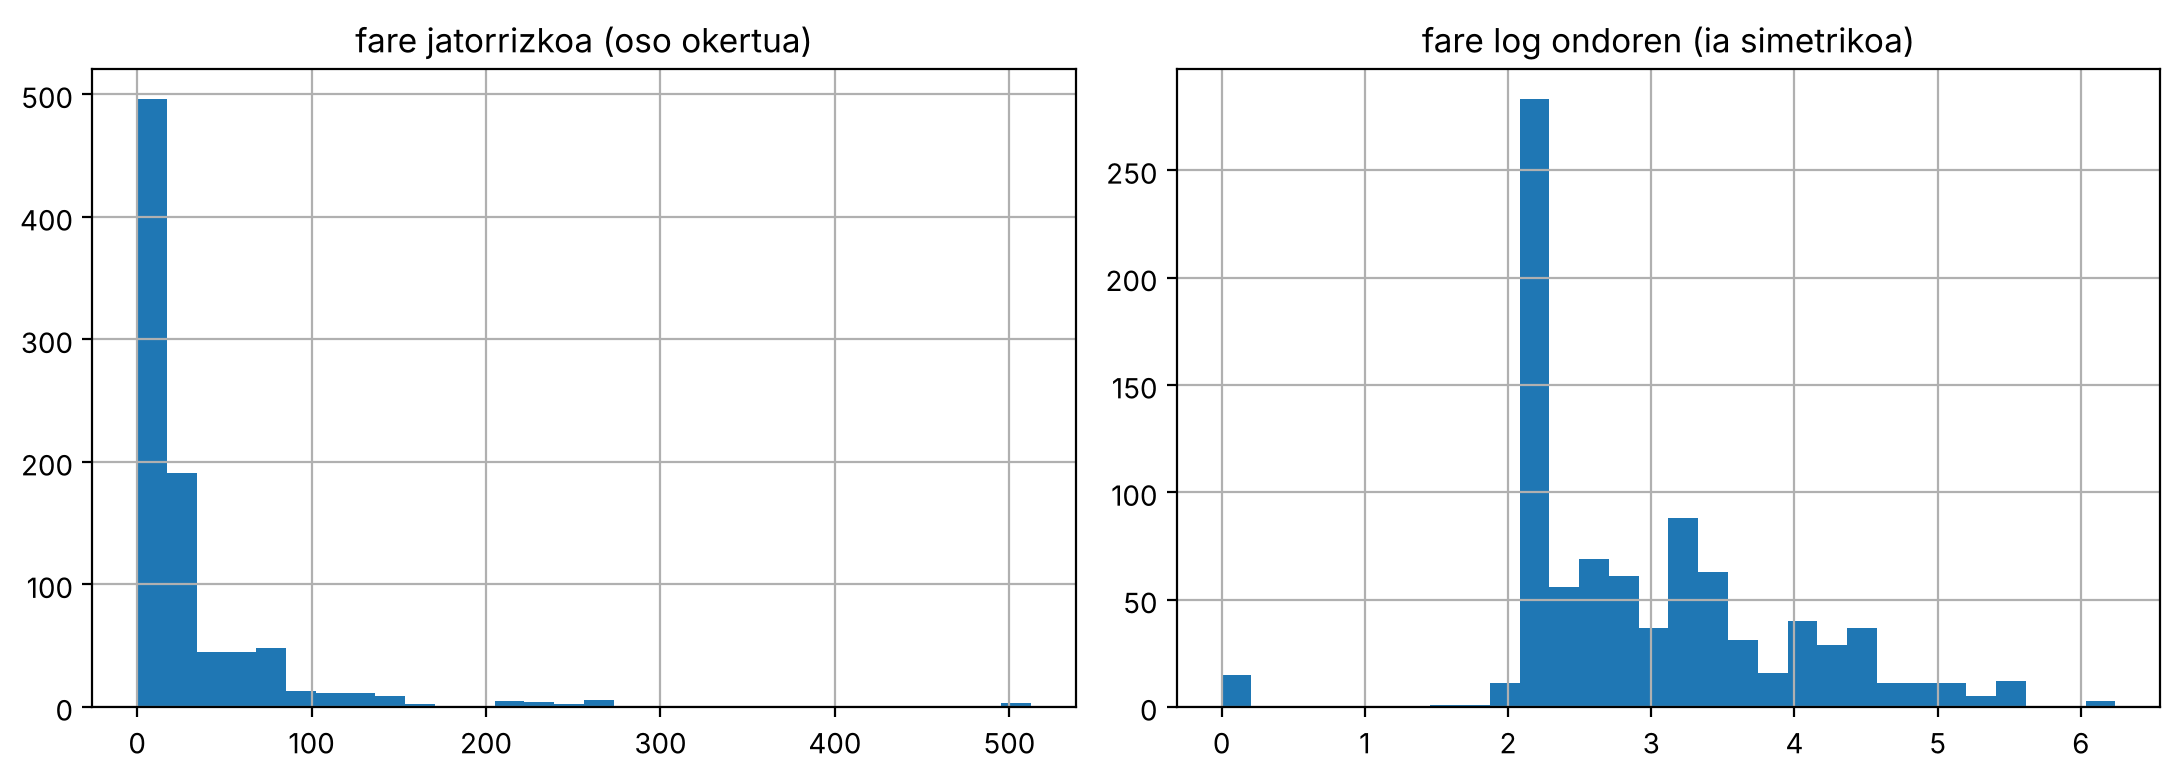

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11,4))
fare.hist(bins=30, ax=ax[0]); ax[0].set_title('fare jatorrizkoa (oso okertua)')
fare_log.hist(bins=30, ax=ax[1]); ax[1].set_title('fare log ondoren (ia simetrikoa)')
plt.tight_layout(); plt.show()